# Multiple Lineare Regression

**Ziel:** Sie trainieren ein Regressionsmodell für **beliebige CSV-Datensätze mit numerischer Zielvariable**. Sie müssen den Python-Code nicht vollständig verstehen: Passen Sie zunächst die **Konfigurationszelle** an, führen Sie die Codezellen von oben nach unten aus und interpretieren Sie die Ergebnisse.

**Ablauf:** CSV hochladen → Daten ansehen → Features und Zielvariable auswählen → Trainieren → Regressionsfunktion und Fehler ausgeben → Eigene Werte eingeben und vorhersagen.

**Beispiele für die Konfiguration:**
- Advertising: `FEATURES = ['TV', 'radio', 'newspaper']`, `TARGET = 'sales'`
- Fußballspieler: `FEATURES = ['goalsTotal', 'age']`, `TARGET = 'marketvalue'` (nur, wenn diese Spalten tatsächlich im CSV vorkommen).

**Hinweis:** Dieses Notebook verwendet eine **multiple lineare Regression** (ohne polynomialen Terme oder kategoriales Encoding). Die Eingabevariablen müssen numerisch sein. Sie können auch nur ein Feature wählen.

## 1. CSV-Datei hochladen

In [ ]:
from google.colab import files
uploaded = files.upload()
if not uploaded:
    raise ValueError('Bitte eine CSV-Datei auswählen.')

Saving Advertising.csv to Advertising.csv


## 2. Daten einlesen und untersuchen

In [ ]:
# @title
import io
import pandas as pd
import numpy as np

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))
# Eventuelle exportierte Indexspalten entfernen
df = df.loc[:, ~df.columns.astype(str).str.match(r'^Unnamed(:|$)')]

print('Datensatz:', filename)
print('Zeilen, Spalten:', df.shape)
print('\nSpalten:', list(df.columns))
print('\nNumerische Spalten:', df.select_dtypes(include='number').columns.tolist())
display(df.head())
display(df.describe(include='number').T.round(2))

Datensatz: Advertising.csv
Zeilen, Spalten: (200, 4)

Spalten: ['TV', 'radio', 'newspaper', 'sales']

Numerische Spalten: ['TV', 'radio', 'newspaper', 'sales']


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.04,85.85,0.7,74.38,149.75,218.82,296.4
radio,200.0,23.26,14.85,0.0,9.98,22.90,36.52,49.6
newspaper,200.0,30.55,21.78,0.3,12.75,25.75,45.10,114.0
sales,200.0,14.02,5.22,1.6,10.38,12.90,17.40,27.0


## 3. Konfiguration – hier ändern Sie die Variablen

Wählen Sie aus den oben angezeigten Spalten **eine oder mehrere numerische Eingabevariablen** und **eine numerische Zielvariable**. Schreibweise und Groß-/Kleinschreibung müssen stimmen. Bei Bedarf `FEATURES` und `TARGET` anpassen und **alle folgenden Zellen erneut ausführen**.

In [ ]:
# ===== KONFIGURATION: NUR HIER ANPASSEN =====
FEATURES = ['TV', 'radio', 'newspaper']   # alternativ z. B. ['goalsTotal', 'age']
TARGET = 'sales'                        # alternativ z. B. 'marketvalue'
TEST_SIZE = 0.20
RANDOM_STATE = 42
# ==========================================

if not isinstance(FEATURES, list) or not FEATURES:
    raise ValueError("FEATURES muss eine nicht-leere Liste sein, z. B. ['TV', 'radio'].")
if len(FEATURES) != len(set(FEATURES)):
    raise ValueError('Bitte kein Feature mehrfach auswählen.')
if TARGET in FEATURES:
    raise ValueError('Die Zielvariable darf nicht zugleich ein Feature sein.')
missing = [col for col in FEATURES + [TARGET] if col not in df.columns]
if missing:
    raise ValueError(f'Spalten nicht gefunden: {missing}. Vorhanden: {list(df.columns)}')
non_numeric = [col for col in FEATURES + [TARGET] if not pd.api.types.is_numeric_dtype(df[col])]
if non_numeric:
    raise ValueError(f'Diese Spalten sind nicht numerisch: {non_numeric}. Wählen Sie numerische Spalten.')

model_df = df[FEATURES + [TARGET]].replace([np.inf, -np.inf], np.nan).dropna().copy()
if len(model_df) < 10:
    raise ValueError('Zu wenige vollständige Beobachtungen (mindestens 10 erforderlich).')
print('Features:', FEATURES)
print('Zielvariable:', TARGET)
print('Verwendbare Beobachtungen:', len(model_df), '(entfernte unvollständige Zeilen:', len(df)-len(model_df), ')')

Features: ['TV', 'radio', 'newspaper']
Zielvariable: sales
Verwendbare Beobachtungen: 200 (entfernte unvollständige Zeilen: 0 )


## 4. Explorative Analyse: Korrelationen und Scatterplots

Die Diagramme zeigen **jeweils einen bivariaten Zusammenhang**. Die multiple Regression betrachtet alle ausgewählten Features gemeinsam.

,TV,radio,newspaper,sales
TV,1.000,0.055,0.057,0.782
radio,0.055,1.000,0.354,0.576
newspaper,0.057,0.354,1.000,0.228
sales,0.782,0.576,0.228,1.000


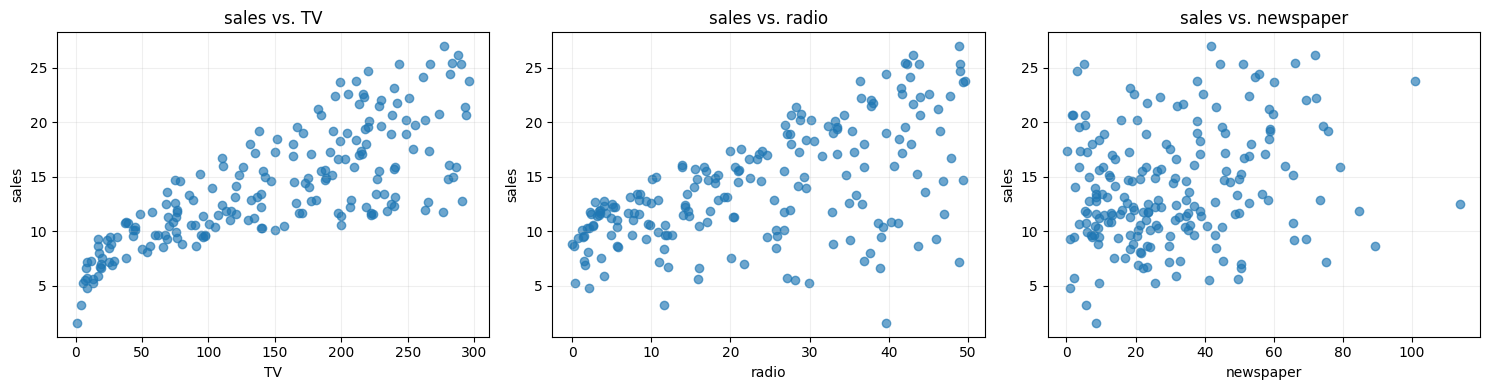

In [ ]:
import matplotlib.pyplot as plt

display(model_df.corr(numeric_only=True).round(3))
fig, axes = plt.subplots(1, len(FEATURES), figsize=(5 * len(FEATURES), 4), squeeze=False)
for ax, feature in zip(axes.ravel(), FEATURES):
    ax.scatter(model_df[feature], model_df[TARGET], alpha=0.65)
    ax.set_xlabel(feature)
    ax.set_ylabel(TARGET)
    ax.set_title(f'{TARGET} vs. {feature}')
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 5. Trainings- und Testdaten aufteilen

80 % werden standardmäßig zum Training genutzt, 20 % zur Bewertung auf bislang ungesehenen Daten.

In [ ]:
from sklearn.model_selection import train_test_split
X = model_df[FEATURES]
y = model_df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print('Training:', len(X_train), '| Test:', len(X_test))

Training: 160 | Test: 40


## 6. Multiple lineare Regression trainieren und Regressionsfunktion anzeigen

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

print(f'Intercept: {model.intercept_:.5f}')
print('Koeffizienten:')
display(pd.DataFrame({'Feature': FEATURES, 'Koeffizient': model.coef_}).round(5))

terms = [f'({coef:+.5f} × {feature})' for feature, coef in zip(FEATURES, model.coef_)]
print('Geschätzte Regressionsfunktion:')
print(f'{TARGET}_vorhergesagt = {model.intercept_:.5f} ' + ' '.join(terms))

Intercept: 2.97907
Koeffizienten:


,Feature,Koeffizient
0,TV,0.04473
1,radio,0.18920
2,newspaper,0.00276


Geschätzte Regressionsfunktion:
sales_vorhergesagt = 2.97907 (+0.04473 × TV) (+0.18920 × radio) (+0.00276 × newspaper)


## 7. Vorhersagen für Testdaten und Modellfehler

**SSE / RSS:** Summe der quadrierten Fehler; **MSE:** mittlerer quadrierter Fehler; **RMSE:** Wurzel des MSE; **MAE:** durchschnittlicher absoluter Fehler; **R²:** Güte relativ zur Mittelwertprognose.

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

y_pred = model.predict(X_test)
resultate = X_test.copy()
resultate['Istwert'] = y_test.to_numpy()
resultate['Prognose'] = y_pred
resultate['Residuum'] = resultate['Istwert'] - resultate['Prognose']
display(resultate.head(10).round(3))

sse = float(np.sum((y_test.to_numpy() - y_pred)**2))
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'SSE/RSS  = {sse:.3f}')
print(f'MSE      = {mse:.3f}')
print(f'RMSE     = {rmse:.3f}')
print('Alle Kennzahlen wurden auf dem TEST-Datensatz berechnet.')

,TV,radio,newspaper,Istwert,Prognose,Residuum
95,163.3,31.6,52.9,16.9,16.408,0.492
15,195.4,47.7,52.9,22.4,20.890,1.510
30,292.9,28.3,43.2,21.4,21.554,-0.154
158,11.7,36.9,45.2,7.3,10.609,-3.309
128,220.3,49.0,3.2,24.7,22.112,2.588
115,75.1,35.0,52.7,12.6,13.106,-0.506
69,216.8,43.9,27.2,22.3,21.057,1.243
170,50.0,11.6,18.4,8.4,7.461,0.939
174,222.4,3.4,13.1,11.5,13.606,-2.106
45,175.1,22.5,31.5,14.9,15.155,-0.255


R²       = 0.899
MAE      = 1.461
MSE      = 3.174
RMSE     = 1.782
SSE/RSS  = 126.964
Alle Kennzahlen wurden auf dem TEST-Datensatz berechnet.


## 8. Tatsächliche und vorhergesagte Zielwerte vergleichen

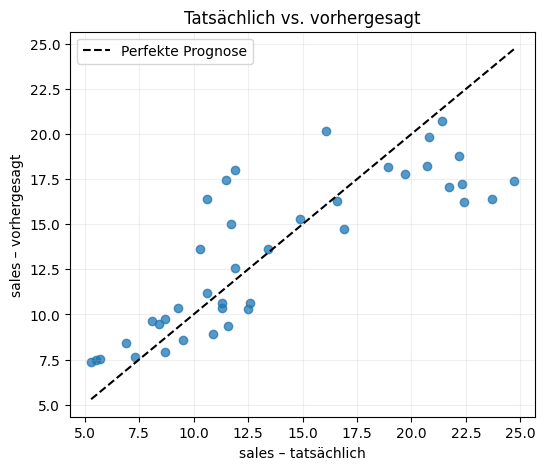

In [ ]:
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_pred, alpha=0.75)
lo = min(y_test.min(), y_pred.min())
hi = max(y_test.max(), y_pred.max())
plt.plot([lo,hi], [lo,hi], linestyle='--', color='black', label='Perfekte Prognose')
plt.xlabel(f'{TARGET} – tatsächlich')
plt.ylabel(f'{TARGET} – vorhergesagt')
plt.title('Tatsächlich vs. vorhergesagt')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 9. Reflexion

1. Welche Eingabevariablen wurden ausgewählt und warum?
2. Wie lautet die geschätzte Regressionsfunktion? Wie interpretieren Sie einen Koeffizienten, **wenn die anderen Features konstant gehalten werden**?
3. Wie groß sind RMSE und R² auf dem Testdatensatz? Welche Einheit hat der RMSE?
4. Vergleichen Sie für einzelne Testfälle **Istwert**, **Prognose** und **Residuum**. Wo liegt das Modell deutlich daneben?
5. Was ändert sich an den Testfehlern, wenn Sie ein Feature entfernen und das Notebook erneut ausführen?

**Hinweis:** Eine Korrelation beweist keine Kausalität. Nichtnumerische Merkmale müssen vor dem Training passend codiert werden; das ist nicht Bestandteil dieser Einführungsübung.